# AgriShift Inundation & Waterlogging Dataset - Part 3: Scientific Diagnostics, Calibration & LightGBM Training

Validates and trains two separate, leak-free early-warning models:
  - **Task A (`label_inundation`):** Sentinel-1 SAR surface water inundation (2017-2025: train 2017-2021, val 2022, test 2023-2025)
  - **Task B (`label_waterlogging`):** Root-zone soil saturation waterlogging (2003-2025: train 2003-2019, val 2020-2021, test 2022-2025, strictly excluding radar features)

### Scientific & Free-Colab Optimizations Applied:
1. **Val-Set Isotonic Probability Calibration & Threshold Tuning:** Calibrates predicted probabilities on `val` and selects the F1-optimal threshold strictly on `val`.
2. **Complete Scientific Visualizations:** Yearly/monthly base-rate & SAR coverage plots, Baseline-Inclusive PR curves (`LightGBM` vs `Persistence`, `Current Score`, `Climatology`, `No-Skill`), Reliability Calibration curves, Normalized Confusion Matrices, and Khulna Division 3-panel Spatial Risk Maps.

### Cell 1 - load cropland panel

In [ ]:
!pip install -q lightgbm

import os
import gc
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, precision_recall_curve,
    confusion_matrix, brier_score_loss,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

# Fallback to local path if Google Drive root directory is read-only or not supported
OUT_DIR = os.environ.get("FLOOD_OUT", "/content/drive/MyDrive/AgriShift_flood_dataset/processed")
MODEL_DIR = os.path.join(OUT_DIR, "models")

try:
    os.makedirs(MODEL_DIR, exist_ok=True)
except OSError:
    print("Warning: Writing to Google Drive failed. Falling back to local runtime environment storage.")
    OUT_DIR = "/content/AgriShift_flood_dataset/processed"
    MODEL_DIR = os.path.join(OUT_DIR, "models")
    os.makedirs(MODEL_DIR, exist_ok=True)

# Check if dataset exists in the determined directory; if not, look in local folder
parquet_path = os.path.join(OUT_DIR, "agrishift_flood_panel.parquet")
if not os.path.exists(parquet_path):
    # Try reading from alternative local directory if it was downloaded locally
    alt_path = "/content/agrishift_flood_panel.parquet"
    if os.path.exists(alt_path):
        panel = pd.read_parquet(alt_path)
    else:
        panel = pd.read_parquet(parquet_path)
else:
    panel = pd.read_parquet(parquet_path)

panel["district"] = panel["district"].replace({"Jhenaidaha": "Jhenaidah"})
crop = panel[panel["is_cropland"] == 1].copy()
del panel
gc.collect()

print(f"Cropland rows: {len(crop):,} | pixels: {crop['pixel_id'].nunique():,} | districts: {crop['district'].nunique()}")

Cropland rows: 3,321,108 | pixels: 12,033 | districts: 10


### Cell 2 - Yearly & Monthly Drift, Seasonality, and Sentinel-1 Coverage Diagnostics

=== Sentinel-1 Surface Inundation by Year (2017-2025) ===
      sar_obs_share  mean_n_obs  inund_frac_mean  inund_anom_mean  inund_rate     rain_mm
year                                                                                     
2017          1.000       5.658            0.052            0.006       0.047  188.716995
2018          0.951       6.572            0.041           -0.002       0.026  116.704002
2019          1.000       6.739            0.035           -0.010       0.018  143.113998
2020          1.000       7.337            0.046            0.001       0.036  149.009003
2021          1.000       6.788            0.050            0.005       0.049  166.634003
2022          1.000       6.560            0.036           -0.010       0.025  110.252998
2023          1.000       6.249            0.033           -0.013       0.016  120.555000
2024          1.000       6.147            0.048            0.003       0.056  148.248001
2025          1.000       6.570           

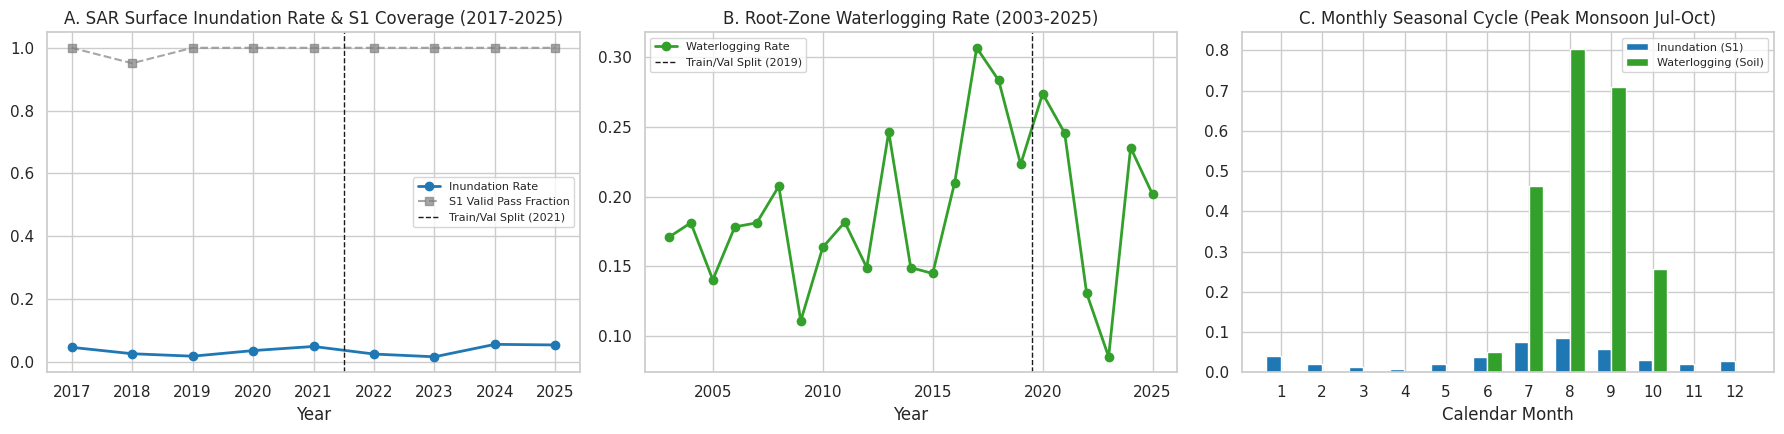

In [ ]:
sar_yr = crop[crop["year"] >= 2017].groupby("year").agg(
    sar_obs_share=("inund_frac", lambda s: s.notna().mean()),
    mean_n_obs=("n_obs", "mean"),
    inund_frac_mean=("inund_frac", "mean"),
    inund_anom_mean=("inund_frac_anom", "mean"),
    inund_rate=("label_inundation", "mean"),
    rain_mm=("rain_mm", "mean"),
)
print("=== Sentinel-1 Surface Inundation by Year (2017-2025) ===")
print(sar_yr.round(3).to_string())

wl_yr = crop.groupby("year").agg(
    swl2_sat_mean=("swl2_sat", "mean"),
    swl2_anom_mean=("swl2_anom", "mean"),
    lswi_anom_mean=("lswi_mean_anom", "mean"),
    wl_rate=("label_waterlogging", "mean"),
    rain_mm=("rain_mm", "mean"),
)
print("\n=== Root-Zone Waterlogging by Year (2003-2025) ===")
print(wl_yr.round(3).to_string())

by_month = crop.groupby("month").agg(
    rain_mm=("rain_mm", "mean"),
    swl2_sat=("swl2_sat", "mean"),
    inund_rate=("label_inundation", "mean"),
    wl_rate=("label_waterlogging", "mean"),
)

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(sar_yr.index, sar_yr["inund_rate"], "o-", color="#1f78b4", lw=2, label="Inundation Rate")
axes[0].plot(sar_yr.index, sar_yr["sar_obs_share"], "s--", color="gray", alpha=0.7, label="S1 Valid Pass Fraction")
axes[0].axvline(2021.5, color="k", ls="--", lw=1, label="Train/Val Split (2021)")
axes[0].set_title("A. SAR Surface Inundation Rate & S1 Coverage (2017-2025)")
axes[0].set_xlabel("Year")
axes[0].legend(fontsize=8)

axes[1].plot(wl_yr.index, wl_yr["wl_rate"], "o-", color="#33a02c", lw=2, label="Waterlogging Rate")
axes[1].axvline(2019.5, color="k", ls="--", lw=1, label="Train/Val Split (2019)")
axes[1].set_title("B. Root-Zone Waterlogging Rate (2003-2025)")
axes[1].set_xlabel("Year")
axes[1].legend(fontsize=8)

axes[2].bar(by_month.index - 0.18, by_month["inund_rate"], width=0.35, color="#1f78b4", label="Inundation (S1)")
axes[2].bar(by_month.index + 0.18, by_month["wl_rate"], width=0.35, color="#33a02c", label="Waterlogging (Soil)")
axes[2].set_xticks(range(1, 13))
axes[2].set_title("C. Monthly Seasonal Cycle (Peak Monsoon Jul-Oct)")
axes[2].set_xlabel("Calendar Month")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig_flood_02_yearly_and_monthly_rates.png"), dpi=150)
plt.show()

### Cell 3 - Separate, Strictly Leak-Free Feature Sets for Each Task

In [ ]:
# Waterlogging spans 2003-2025, so it MUST NOT use Sentinel-1 columns (which are all NaN before 2017)
EXCL_PREFIX = ("target_", "label_")
EXCL_COMMON = {
    "pixel_id", "date", "district", "year", "landcover", "is_cropland",
    "split_sar", "split_opt", "spatial_fold", "swl2_porosity",
}
SAR_ONLY_COLS = {
    "water_freq", "water_peak", "n_obs", "vv_median", "perm_water",
    "inund_mean", "inund_frac", "inund_frac_clim_mean", "inund_frac_clim_std",
    "inund_frac_anom", "inund_frac_z",
    "inund_frac_lag1", "inund_frac_lag2", "inund_frac_lag3",
}

FEATURES_INUND = [
    c for c in crop.columns
    if not c.startswith(EXCL_PREFIX)
    and c not in EXCL_COMMON
    and pd.api.types.is_numeric_dtype(crop[c])
]
FEATURES_WL = [c for c in FEATURES_INUND if c not in SAR_ONLY_COLS]
print(f"Inundation features: {len(FEATURES_INUND)} | Waterlogging features (no SAR): {len(FEATURES_WL)}")

Inundation features: 105 | Waterlogging features (no SAR): 91


### Cell 4 - Calibrated LightGBM Training & Evaluation Helper

In [ ]:
def best_f1_thr(y_true, prob):
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return float(t[int(np.nanargmax(f1))]) if len(t) else 0.5


def metrics(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return dict(
        roc_auc=float(roc_auc_score(y_true, prob)) if len(np.unique(y_true)) > 1 else np.nan,
        pr_auc=float(average_precision_score(y_true, prob)) if len(np.unique(y_true)) > 1 else np.nan,
        brier=float(brier_score_loss(y_true, np.clip(prob, 0, 1))),
        f1=float(f1_score(y_true, pred, zero_division=0)),
        precision=float(precision_score(y_true, pred, zero_division=0)),
        recall=float(recall_score(y_true, pred, zero_division=0)),
        thr=float(thr),
        pos_rate=float(np.mean(y_true)),
    )


LGB_PARAMS = dict(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=63,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=1.0,
    reg_lambda=5.0,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)


def run_task(df_in, split_col, curr_label, cont_col, target_col, features, task_name):
    sub = df_in[df_in[split_col].isin(["train", "val", "test"])].dropna(
        subset=[target_col, curr_label, cont_col]
    )
    tr = sub[sub[split_col] == "train"]
    va = sub[sub[split_col] == "val"]
    te = sub[sub[split_col] == "test"]

    y_tr = tr[target_col].astype(int).values
    y_va = va[target_col].astype(int).values
    y_te = te[target_col].astype(int).values

    # Baseline 1: Persistence (current state continues next month)
    p_pers_te = te[curr_label].values

    # Baseline 2: Current continuous wetness score (`inund_frac` or `swl2_sat`)
    s_va = va[cont_col].clip(0, 1).values
    s_te = te[cont_col].clip(0, 1).values
    thr_s = best_f1_thr(y_va, s_va)

    # Baseline 3: Per-pixel-month training climatology
    clim = tr.groupby(["pixel_id", "month"], sort=False)[target_col].mean().rename("c")
    prior = float(y_tr.mean())
    c_va = va[["pixel_id", "month"]].merge(clim, on=["pixel_id", "month"], how="left")["c"].fillna(prior).values
    c_te = te[["pixel_id", "month"]].merge(clim, on=["pixel_id", "month"], how="left")["c"].fillna(prior).values
    thr_c = best_f1_thr(y_va, c_va)

    # LightGBM Classifier + Val-Set Isotonic Calibration
    clf = lgb.LGBMClassifier(**LGB_PARAMS)
    clf.fit(
        tr[features], y_tr,
        eval_set=[(va[features], y_va)],
        eval_metric="average_precision",
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    raw_va = clf.predict_proba(va[features])[:, 1]
    raw_te = clf.predict_proba(te[features])[:, 1]

    iso = IsotonicRegression(out_of_bounds="clip")
    iso.fit(raw_va, y_va)
    cal_va = iso.transform(raw_va)
    cal_te = iso.transform(raw_te)
    thr_m = best_f1_thr(y_va, cal_va)

    out = pd.DataFrame({
        "Persistence (now)": metrics(y_te, p_pers_te, 0.5),
        f"Current {cont_col} Score": metrics(y_te, s_te, thr_s),
        "Pixel-Month Climatology": metrics(y_te, c_te, thr_c),
        "LightGBM (Calibrated)": metrics(y_te, cal_te, thr_m),
    }).T
    print(f"\n=== {task_name} (train={len(tr):,}, val={len(va):,}, test={len(te):,}) ===")
    print(out.round(4).to_string())

    return dict(
        clf=clf, iso=iso, thr=thr_m, features=features,
        y_te=y_te, raw_te=raw_te, cal_te=cal_te,
        p_pers_te=p_pers_te, s_te=s_te, c_te=c_te,
        te_meta=te[["pixel_id", "district", "lon", "lat", "year", "month"]].copy(),
    )

### Cell 5 - Run Task A (Surface Inundation) & Task B (Root-Zone Waterlogging)

In [ ]:
inund_artifacts = {}
for h in (1, 2):
    inund_artifacts[h] = run_task(
        crop, "split_sar", "label_inundation", "inund_frac",
        f"label_inundation_next{h}", FEATURES_INUND,
        f"Task A: SAR Surface Inundation +{h} Month(s) Ahead",
    )
    joblib.dump(
        {"model": inund_artifacts[h]["clf"], "calibrator": inund_artifacts[h]["iso"],
         "threshold": inund_artifacts[h]["thr"], "features": FEATURES_INUND},
        os.path.join(MODEL_DIR, f"flood_inundation_lgbm_h{h}.joblib"),
    )

wl_artifacts = {}
for h in (1, 2):
    wl_artifacts[h] = run_task(
        crop, "split_opt", "label_waterlogging", "swl2_sat",
        f"label_waterlogging_next{h}", FEATURES_WL,
        f"Task B: Root-Zone Waterlogging +{h} Month(s) Ahead",
    )
    joblib.dump(
        {"model": wl_artifacts[h]["clf"], "calibrator": wl_artifacts[h]["iso"],
         "threshold": wl_artifacts[h]["thr"], "features": FEATURES_WL},
        os.path.join(MODEL_DIR, f"flood_waterlogging_lgbm_h{h}.joblib"),
    )


=== Task A: SAR Surface Inundation +1 Month(s) Ahead (train=714,284, val=144,396, test=421,155) ===
                          roc_auc  pr_auc   brier      f1  precision  recall     thr  pos_rate
Persistence (now)          0.7041  0.2105  0.0479  0.4320     0.4308  0.4333  0.5000    0.0421
Current inund_frac Score   0.8223  0.2991  0.0342  0.3849     0.3241  0.4738  0.2004    0.0421
Pixel-Month Climatology    0.8018  0.2065  0.0357  0.3233     0.3294  0.3175  0.3333    0.0421
LightGBM (Calibrated)      0.9378  0.4738  0.0295  0.4723     0.3896  0.5997  0.1784    0.0421

=== Task A: SAR Surface Inundation +2 Month(s) Ahead (train=713,692, val=144,396, test=409,122) ===
                          roc_auc  pr_auc   brier      f1  precision  recall     thr  pos_rate
Persistence (now)          0.6142  0.1004  0.0635  0.2620     0.2625  0.2614  0.5000    0.0431
Current inund_frac Score   0.7001  0.1637  0.0409  0.2552     0.2198  0.3042  0.2064    0.0431
Pixel-Month Climatology    0.8028  0.2

### Cell 6 - Scientific Visualization: PR Curves (with Baselines), Calibration & Confusion Matrices

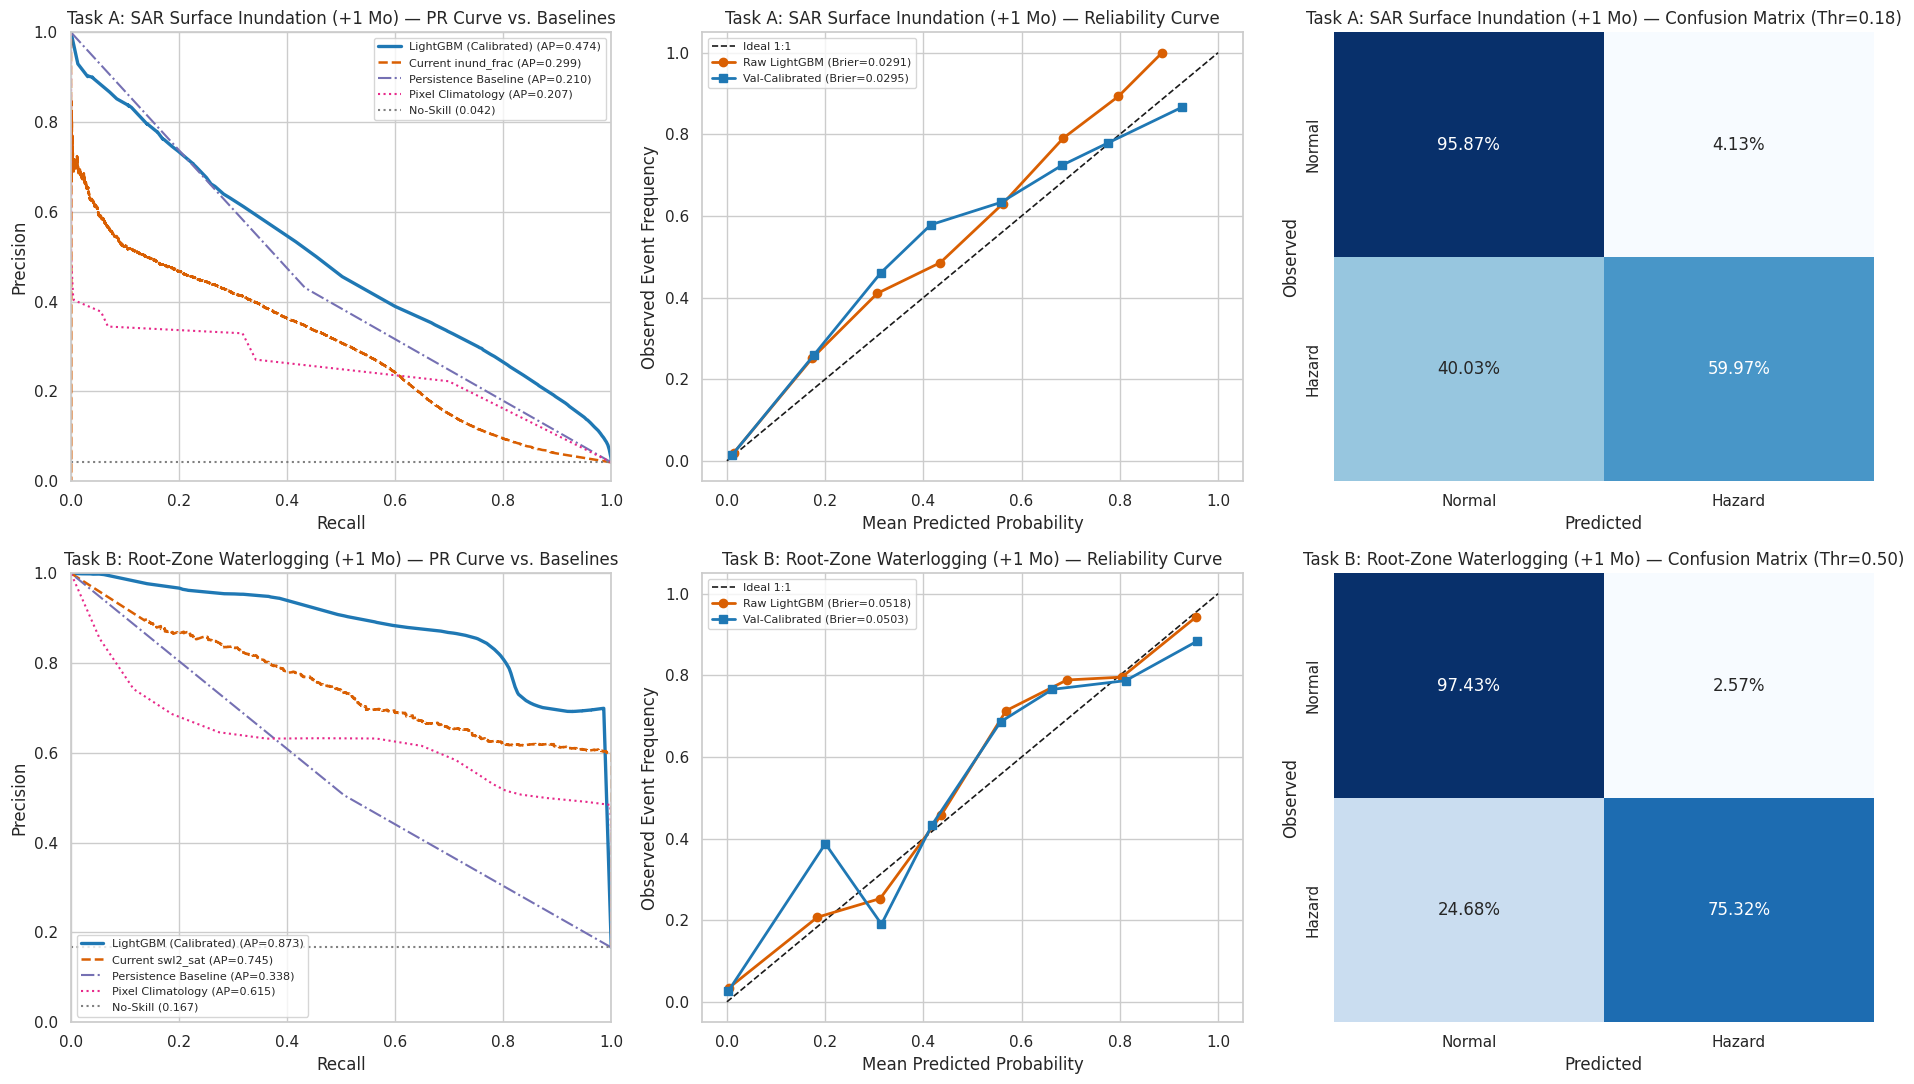

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11))

for row_idx, (title, art, score_label) in enumerate([
    ("Task A: SAR Surface Inundation (+1 Mo)", inund_artifacts[1], "Current inund_frac"),
    ("Task B: Root-Zone Waterlogging (+1 Mo)", wl_artifacts[1], "Current swl2_sat"),
]):
    y_te = art["y_te"]
    cal_te = art["cal_te"]
    raw_te = art["raw_te"]
    base_rate = float(np.mean(y_te))

    # 1. Baseline-Inclusive Precision-Recall Curve
    ax_pr = axes[row_idx, 0]
    for bname, probs, col, ls, lw in [
        ("LightGBM (Calibrated)", cal_te, "#1f78b4", "-", 2.4),
        (score_label, art["s_te"], "#d95f02", "--", 1.8),
        ("Persistence Baseline", art["p_pers_te"], "#7570b3", "-.", 1.5),
        ("Pixel Climatology", art["c_te"], "#e7298a", ":", 1.5),
    ]:
        if len(np.unique(y_te)) > 1:
            p_c, r_c, _ = precision_recall_curve(y_te, probs)
            ap = average_precision_score(y_te, probs)
            ax_pr.plot(r_c, p_c, color=col, ls=ls, lw=lw, label=f"{bname} (AP={ap:.3f})")
    ax_pr.axhline(base_rate, color="gray", ls=":", label=f"No-Skill ({base_rate:.3f})")
    ax_pr.set_title(f"{title} — PR Curve vs. Baselines")
    ax_pr.set_xlabel("Recall")
    ax_pr.set_ylabel("Precision")
    ax_pr.set_xlim(0, 1)
    ax_pr.set_ylim(0, 1)
    ax_pr.legend(fontsize=8)

    # 2. Calibration Reliability Curve
    ax_cal = axes[row_idx, 1]
    ax_cal.plot([0, 1], [0, 1], "k--", lw=1.2, label="Ideal 1:1")
    for cname, probs, col, mk in [
        ("Raw LightGBM", raw_te, "#d95f02", "o"),
        ("Val-Calibrated", cal_te, "#1f78b4", "s"),
    ]:
        if len(np.unique(y_te)) > 1:
            fp, mp = calibration_curve(y_te, np.clip(probs, 0, 1), n_bins=8, strategy="uniform")
            bs = brier_score_loss(y_te, np.clip(probs, 0, 1))
            ax_cal.plot(mp, fp, marker=mk, color=col, lw=2, label=f"{cname} (Brier={bs:.4f})")
    ax_cal.set_title(f"{title} — Reliability Curve")
    ax_cal.set_xlabel("Mean Predicted Probability")
    ax_cal.set_ylabel("Observed Event Frequency")
    ax_cal.legend(fontsize=8)

    # 3. Normalized Confusion Matrix
    ax_cm = axes[row_idx, 2]
    preds = (cal_te >= art["thr"]).astype(int)
    cm = confusion_matrix(y_te, preds, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2%", cmap="Blues", ax=ax_cm, cbar=False,
                xticklabels=["Normal", "Hazard"], yticklabels=["Normal", "Hazard"])
    ax_cm.set_title(f"{title} — Confusion Matrix (Thr={art['thr']:.2f})")
    ax_cm.set_xlabel("Predicted")
    ax_cm.set_ylabel("Observed")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig_flood_03_pr_calibration_cm.png"), dpi=150)
plt.show()

### Cell 7 - 5-Fold 0.25-deg Spatial Block Cross-Validation (Optional Benchmark)

In [ ]:
RUN_SPATIAL_CV = False  # Set to True if you want 5-fold spatial CV
if RUN_SPATIAL_CV:
    MAX_SPATIAL_TRAIN = 250_000
    for name, split_col, curr_col, target_col, feats in [
        ("Surface Inundation +1m", "split_sar", "label_inundation", "label_inundation_next1", FEATURES_INUND),
        ("Root-Zone Waterlogging +1m", "split_opt", "label_waterlogging", "label_waterlogging_next1", FEATURES_WL),
    ]:
        sub = crop[crop[split_col].isin(["train", "test"])].dropna(subset=[target_col, curr_col])
        tr_all = sub[sub[split_col] == "train"]
        te_all = sub[sub[split_col] == "test"]
        rows = []
        for k in sorted(sub["spatial_fold"].unique()):
            tr = tr_all[tr_all["spatial_fold"] != k]
            te = te_all[te_all["spatial_fold"] == k]
            if len(te) == 0 or te[target_col].nunique() < 2:
                continue
            if len(tr) > MAX_SPATIAL_TRAIN:
                tr = tr.sample(n=MAX_SPATIAL_TRAIN, random_state=42 + int(k))
            clf = lgb.LGBMClassifier(**{**LGB_PARAMS, "n_estimators": 400})
            clf.fit(tr[feats], tr[target_col].astype(int))
            p = clf.predict_proba(te[feats])[:, 1]
            y = te[target_col].astype(int).values
            rows.append(dict(
                fold=int(k),
                n_test=len(te),
                model_pr_auc=average_precision_score(y, p),
                persist_pr_auc=average_precision_score(y, te[curr_col].values),
                model_roc_auc=roc_auc_score(y, p),
            ))
            del clf
            gc.collect()
        df_f = pd.DataFrame(rows)
        print(f"\n=== Spatial Block CV: {name} ===")
        print(df_f.round(4).to_string(index=False))
        if len(df_f) > 0:
            print(df_f[["model_pr_auc", "persist_pr_auc", "model_roc_auc"]].agg(["mean", "std"]).round(4))


else:
    print("Skipped 5-Fold Spatial CV to save time. Primary models are already trained and saved!")

Skipped 5-Fold Spatial CV to save time. Primary models are already trained and saved!


### Cell 8 - Khulna Division Geospatial Maps & Feature Importance

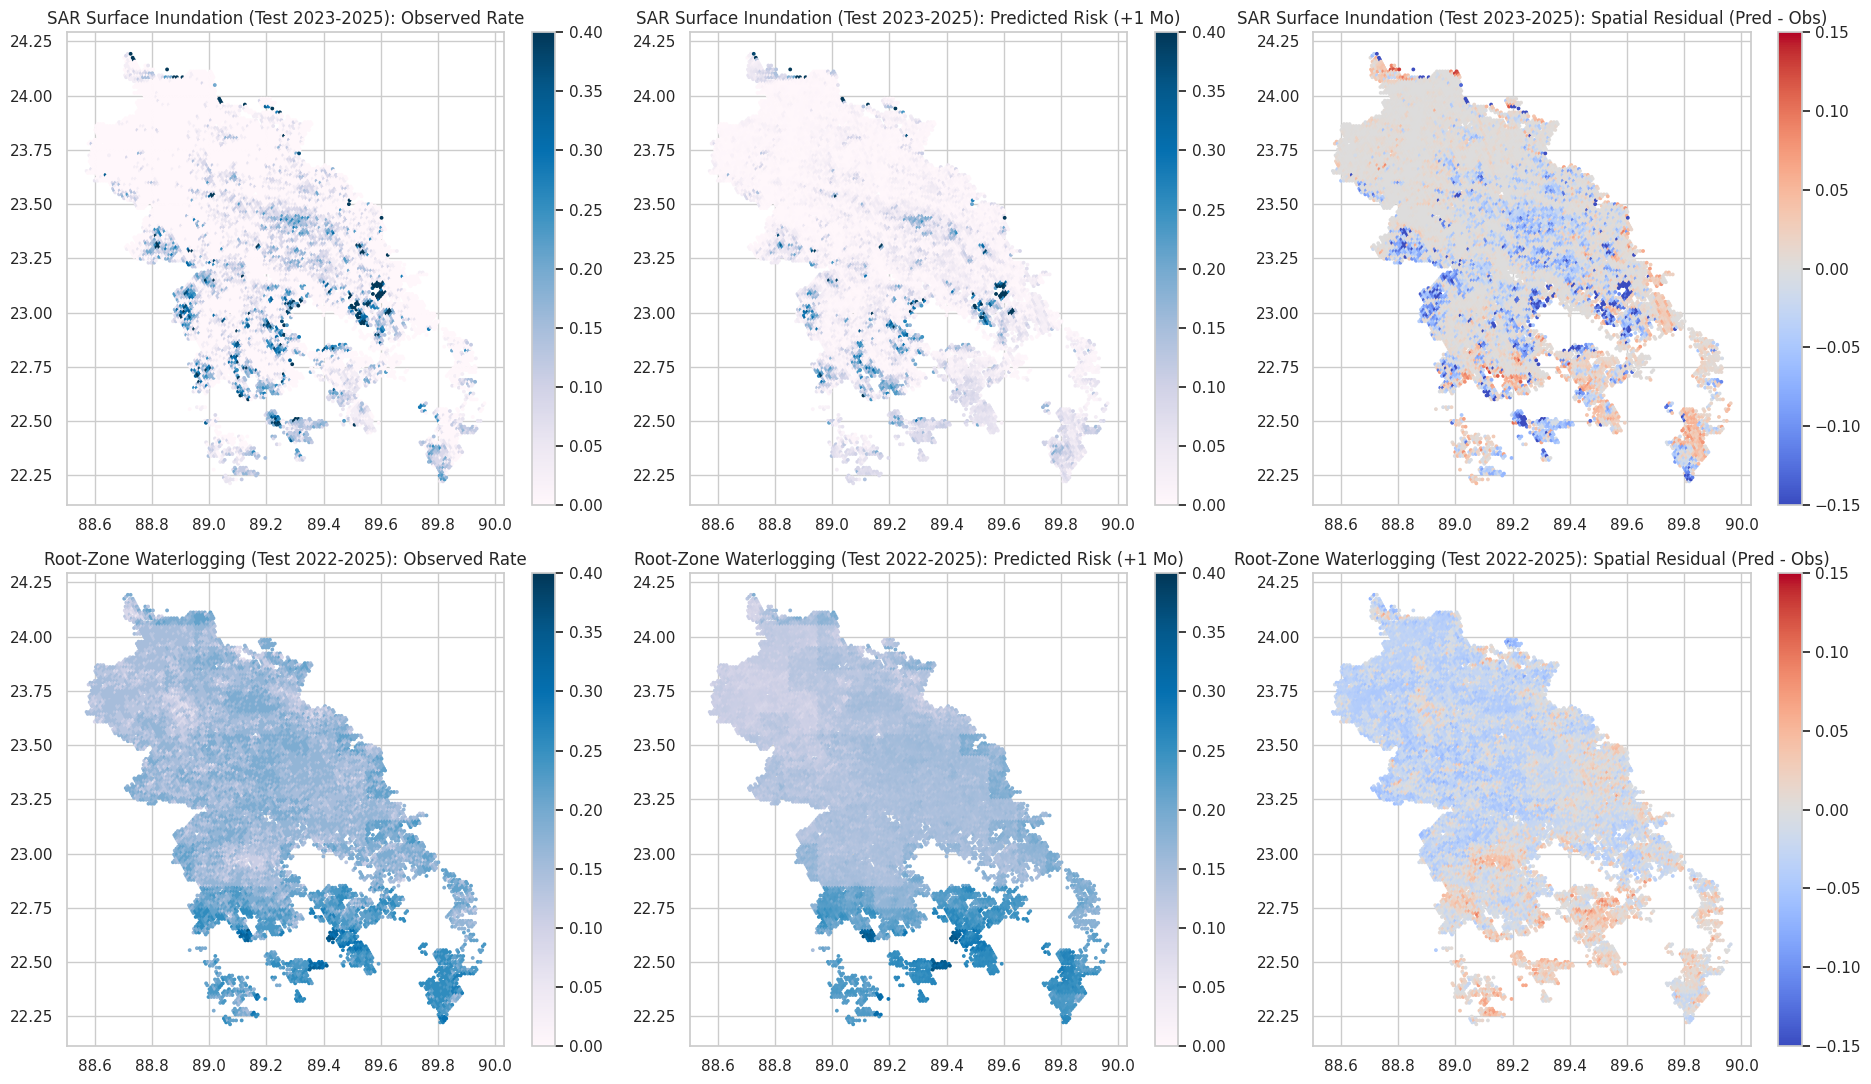


=== Top 15 Features: Inundation +1m ===
lon                    236
lat                    222
inund_frac_clim_std    198
runoff_mm_lag1         196
rain_mm_lag3           164
spi3                   162
rain_mm_lag2           155
era5_rain_mm           153
hnd                    133
runoff_mm_lag3         128
swl3_clim_std          125
inund_frac_anom        112
vv_median              109
elevation              104
runoff_mm_lag2         100

=== Top 15 Features: Waterlogging +1m ===
runoff_mm_lag3     519
rain_mm_lag3       462
era5_rain_mm       410
swl2_sat_lag2      393
rain_mm_lag2       370
lat                347
et_mm              321
runoff_mm_lag2     315
rain_mm_lag1       312
swl2_sat_lag3      307
spi3               287
swl2_roll6_mean    287
lswi_mean_z        285
runoff_mm_lag1     245
swl2_lag3          245


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
for row_idx, (h_title, art) in enumerate([
    ("SAR Surface Inundation (Test 2023-2025)", inund_artifacts[1]),
    ("Root-Zone Waterlogging (Test 2022-2025)", wl_artifacts[1]),
]):
    m_df = art["te_meta"].copy()
    m_df["obs"] = art["y_te"]
    m_df["pred"] = art["cal_te"]
    m_df["err"] = m_df["pred"] - m_df["obs"]
    pm = m_df.groupby(["pixel_id", "lon", "lat"], observed=True).agg(
        obs=("obs", "mean"), pred=("pred", "mean"), err=("err", "mean")
    ).reset_index()

    sc0 = axes[row_idx, 0].scatter(pm["lon"], pm["lat"], c=pm["obs"], s=3, cmap="PuBu", vmin=0, vmax=0.4)
    axes[row_idx, 0].set_title(f"{h_title}: Observed Rate")
    plt.colorbar(sc0, ax=axes[row_idx, 0])

    sc1 = axes[row_idx, 1].scatter(pm["lon"], pm["lat"], c=pm["pred"], s=3, cmap="PuBu", vmin=0, vmax=0.4)
    axes[row_idx, 1].set_title(f"{h_title}: Predicted Risk (+1 Mo)")
    plt.colorbar(sc1, ax=axes[row_idx, 1])

    sc2 = axes[row_idx, 2].scatter(pm["lon"], pm["lat"], c=pm["err"], s=3, cmap="coolwarm", vmin=-0.15, vmax=0.15)
    axes[row_idx, 2].set_title(f"{h_title}: Spatial Residual (Pred - Obs)")
    plt.colorbar(sc2, ax=axes[row_idx, 2])

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig_flood_04_spatial_maps.png"), dpi=150)
plt.show()

for title, art in [("Inundation +1m", inund_artifacts[1]), ("Waterlogging +1m", wl_artifacts[1])]:
    imp = pd.Series(art["clf"].feature_importances_, index=art["features"]).sort_values(ascending=False).head(15)
    print(f"\n=== Top 15 Features: {title} ===")
    print(imp.to_string())